In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

In [27]:
raw_data_path = "../data/raw/Reviews.csv"
df = pd.read_csv(raw_data_path)

print(f"Raw dataset shape: {df.shape}")
print("\n--- Missing Value Count ---")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head(3)

Raw dataset shape: (568454, 10)

--- Missing Value Count ---
ProfileName    26
Summary        27
dtype: int64


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...


In [28]:
initial_rows = len(df)
df = df.drop_duplicates(subset=['UserId', 'Time', 'Text'], keep='first')
dedup_removed = initial_rows - len(df)
print(f"True duplicates removed: {dedup_removed:,} (Rows remaining: {len(df):,})")

bad_helpfulness = df[df['HelpfulnessNumerator'] > df['HelpfulnessDenominator']]
df = df[~df.index.isin(bad_helpfulness.index)]
print(f"Broken helpfulness rows removed: {len(bad_helpfulness)}")
print(f"Clean row count after quality checks: {len(df):,}")

True duplicates removed: 174,562 (Rows remaining: 393,892)
Broken helpfulness rows removed: 2
Clean row count after quality checks: 393,890


In [29]:
# 1. Fill missing summaries with "" to retain valid review text & rating scores
df['Summary'] = df['Summary'].fillna('')

# 2. Drop user identity columns. 'Id' is deliberately KEPT as a stable review identifier
#    (traceability back to raw Reviews.csv). It is never a model input.
cols_to_drop = ['UserId', 'ProfileName']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns], errors='ignore')

# 3. Create full combined review text (Summary + Text)
df['full_text'] = (df['Summary'] + " " + df['Text']).str.strip()

# 4. Integrity checks (keep this output as leakage/cleaning evidence)
assert 'Id' in df.columns, "Id column was lost"
assert df['Id'].is_unique, "Id values are not unique"
assert len(df) == 393_890, f"Unexpected row count: {len(df):,}"

print("Remaining columns:", df.columns.tolist())
print(f"Rows: {len(df):,} | Unique Ids: {df['Id'].nunique():,}")

Remaining columns: ['Id', 'ProductId', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'full_text']
Rows: 393,890 | Unique Ids: 393,890


In [30]:
df['datetime'] = pd.to_datetime(df['Time'], unit='s')
df['review_year'] = df['datetime'].dt.year
df['review_month'] = df['datetime'].dt.month

df['helpfulness_ratio'] = np.where(
    df['HelpfulnessDenominator'] > 0,
    df['HelpfulnessNumerator'] / df['HelpfulnessDenominator'],
    0.0
)

df['summary_length'] = df['Summary'].str.len()
df['text_length'] = df['Text'].str.len()
df['text_word_count'] = df['full_text'].str.split().str.len()

df['sentiment_label'] = np.select(
    [df['Score'] >= 4, df['Score'] <= 2],
    ['positive', 'negative'],
    default='neutral'
)

In [31]:
df = df.drop(columns=['Time', 'HelpfulnessNumerator', 'HelpfulnessDenominator'])
print("Final columns:", df.columns.tolist())

Final columns: ['Id', 'ProductId', 'Score', 'Summary', 'Text', 'full_text', 'datetime', 'review_year', 'review_month', 'helpfulness_ratio', 'summary_length', 'text_length', 'text_word_count', 'sentiment_label']


C:\Users\Ishaan\AppData\Local\Temp\ipykernel_13280\3383893988.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Score', ax=axes[0, 0], palette='Blues_d')
C:\Users\Ishaan\AppData\Local\Temp\ipykernel_13280\3383893988.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Score', y='text_word_count', ax=axes[1, 0], showfliers=False, palette='Blues_d')


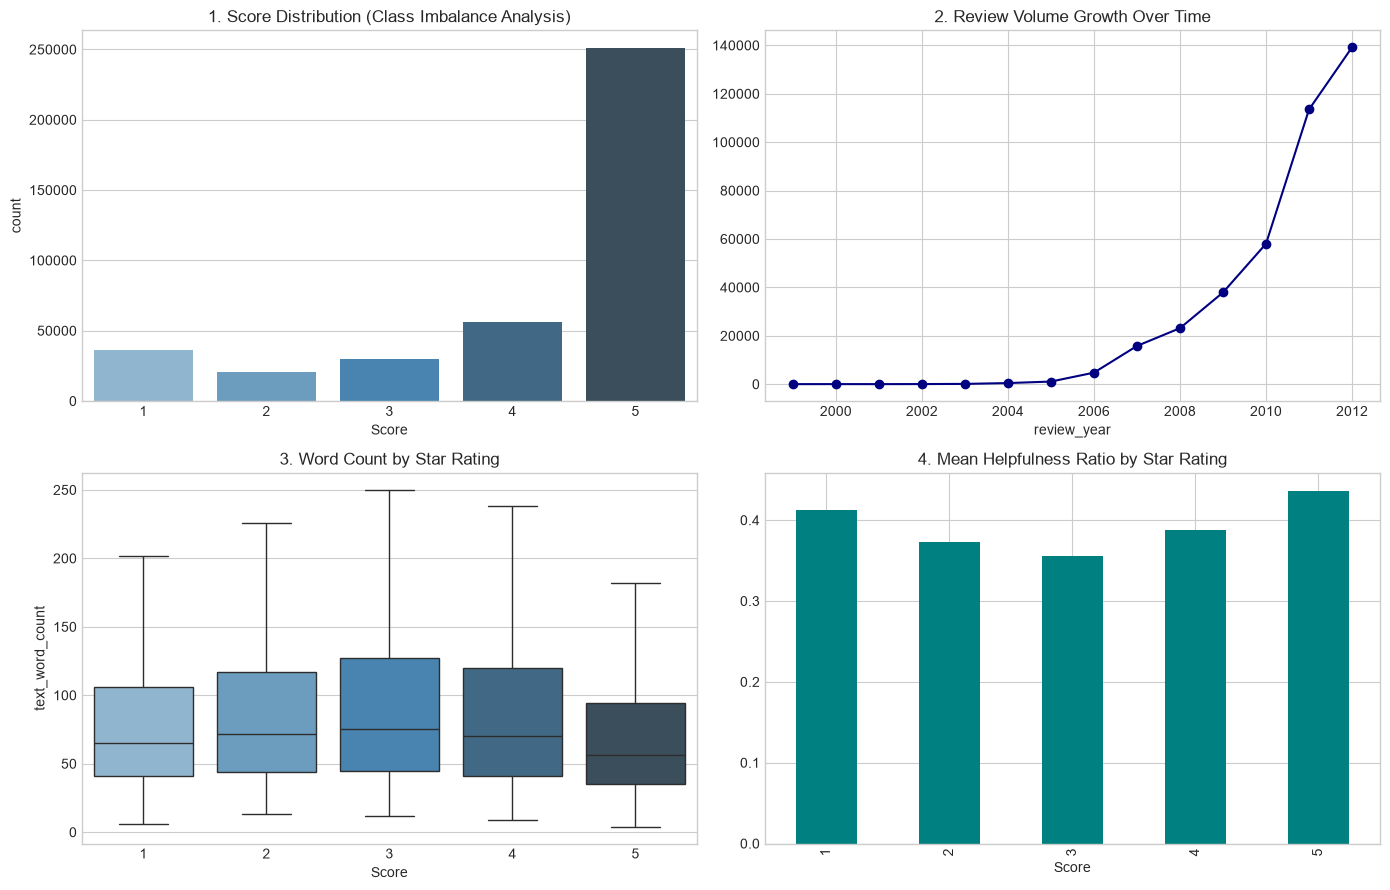

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Rating Distribution
sns.countplot(data=df, x='Score', ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('1. Score Distribution (Class Imbalance Analysis)')

# 2. Review Volume Trend over Time
df.groupby('review_year')['Score'].count().plot(kind='line', marker='o', ax=axes[0, 1], color='navy')
axes[0, 1].set_title('2. Review Volume Growth Over Time')

# 3. Review Word Count by Star Rating
sns.boxplot(data=df, x='Score', y='text_word_count', ax=axes[1, 0], showfliers=False, palette='Blues_d')
axes[1, 0].set_title('3. Word Count by Star Rating')

# 4. Average Helpfulness Ratio by Score
df.groupby('Score')['helpfulness_ratio'].mean().plot(kind='bar', ax=axes[1, 1], color='teal')
axes[1, 1].set_title('4. Mean Helpfulness Ratio by Star Rating')

plt.tight_layout()
plt.show()

In [33]:
# ============================================================================
# PRE-EXPORT ASSERTIONS + EXPORT
# ============================================================================
import pandas as pd

output_path = '../data/processed/reviews_cleaned.csv'

assert 'Id' in df.columns, "CRITICAL: Id column is missing!"
assert df['Id'].is_unique, "CRITICAL: Id column contains duplicates!"
assert pd.api.types.is_integer_dtype(df['Id']), f"Id should be integer, got {df['Id'].dtype}"
assert len(df) == 393_890, f"CRITICAL: Expected 393,890 rows, got {len(df):,}"

print("=" * 70)
print("PRE-EXPORT VALIDATION")
print(f"  Id is unique:      {df['Id'].is_unique}")
print(f"  Id dtype:          {df['Id'].dtype}")
print(f"  Final row count:   {len(df):,}")
print(f"  Id range:          {df['Id'].min()} to {df['Id'].max()}")
print("=" * 70)

df.to_csv(output_path, index=False)

# Reload check: confirm the SAVED FILE has Id, not just the in-memory dataframe
saved = pd.read_csv(output_path, usecols=['Id'])
assert len(saved) == len(df) and saved['Id'].is_unique, "Saved file failed the Id check"
print(f"Exported and re-verified: {output_path} ({len(saved):,} rows, Id preserved)")

PRE-EXPORT VALIDATION
  Id is unique:      True
  Id dtype:          int64
  Final row count:   393,890
  Id range:          1 to 568454
Exported and re-verified: ../data/processed/reviews_cleaned.csv (393,890 rows, Id preserved)


In [34]:
# Cell 17: Save Processed Dataset for Week 2 NLP Tasks
output_path = "../data/processed/reviews_cleaned.csv"
df.to_csv(output_path, index=False)
print(f"✅ Notebook 1 Complete! Saved {len(df):,} clean rows to '{output_path}'.")

✅ Notebook 1 Complete! Saved 393,890 clean rows to '../data/processed/reviews_cleaned.csv'.
